# 4. Transit light curves

`lazuli-exo` also renders the time domain. `obs.light_curves()` turns a
simulated spectrum into one or more transit light curves — white-light, or
split into wavelength bands so you can see the transit depth change with
colour.

The shape is a **quadratically limb-darkened** transit computed by numpy-only
numerical disk integration, with geometry taken from the frozen NEA target
registry and limb-darkening coefficients from per-planet exotic-ld tables.
Planets with no registry entry or no LD table fall back to a b = 0 trapezoid;
`meta["shape"]` always records which model was used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("lazuli_exo", lazuli_exo.__file__)

lazuli_exo /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/lazuli-exo/src/lazuli_exo/__init__.py


## The white-light curve

With `n_groups=1` every spectral bin is combined into a single light curve.
The observation window is ±t<sub>14</sub> around mid-transit — the equal
out-of-transit baseline the noise tables assume — sampled at the instrument's
native integration time.

In [2]:
PLANET = "WASP-39 b"

obs = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=100)
lc = obs.light_curves(n_groups=1, seed=0)

print(f"labels:      {lc.labels}")
print(f"time_hr:     {lc.time_hr.size} samples, "
      f"{lc.time_hr[0]:+.2f} to {lc.time_hr[-1]:+.2f} h")
print(f"cadence:     {lc.cadence_s:.2f} s")
print(f"t14:         {lc.t14_s:.1f} s  ({lc.t14_s / 3600:.2f} h)")
print(f"depth:       {lc.depth[0] * 100:.4f} %")
print(f"sigma/point: {lc.sigma_point[0] * 1e6:.1f} ppm")
print(f"\nmeta: {lc.meta}")

labels:      ['white light']
time_hr:     222 samples, -2.78 to +2.78 h
cadence:     90.56 s
t14:         10091.5 s  (2.80 h)
depth:       2.2690 %
sigma/point: 61.1 ppm

meta: {'planet': 'WASP-39 b', 'scenario': 'clear', 'n_transits': 1, 'shape': 'quadratic-ld', 'b': 0.532570994641176, 'a_over_rs': 11.39}


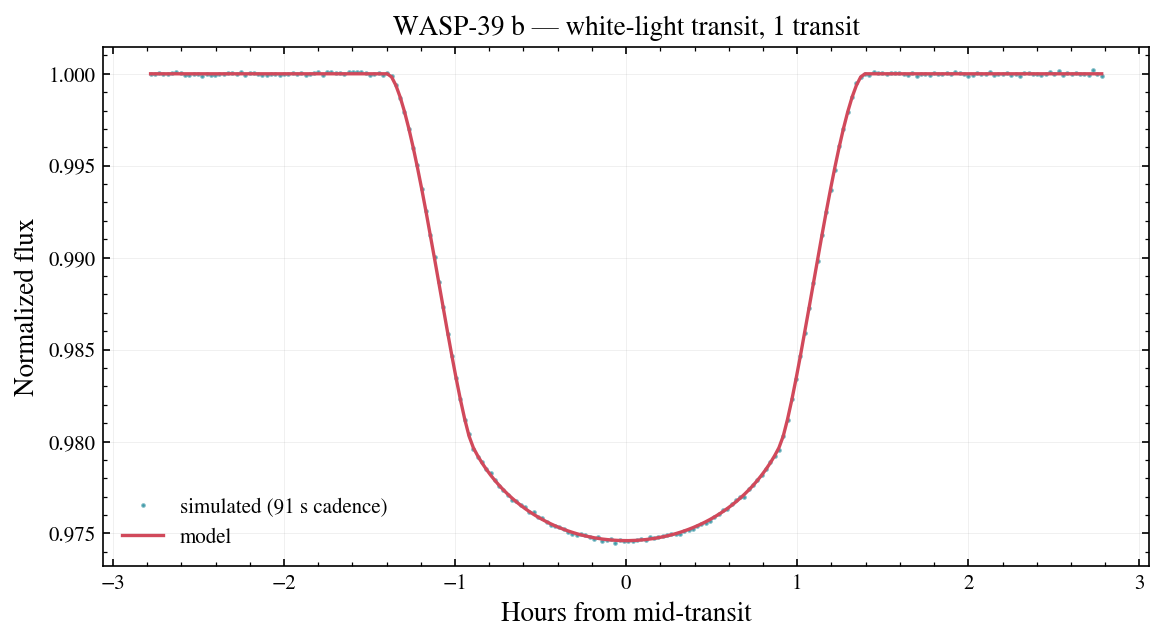

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(lc.time_hr, lc.flux[0], ".", ms=2.5, alpha=0.5,
        label=f"simulated ({lc.cadence_s:.0f} s cadence)")
ax.plot(lc.time_hr, lc.flux_model[0], lw=1.6, label="model")

ax.set_xlabel("Hours from mid-transit")
ax.set_ylabel("Normalized flux")
ax.set_title(f"{PLANET} — white-light transit, 1 transit")
ax.legend(frameon=False)
plt.show()

## Wavelength-banded light curves

`n_groups > 1` splits the spectrum into contiguous bands of equal bin count.
The geometry is shared, but each band gets its own depth and its own limb
darkening — so the curves are not simply scaled copies of one another.

In [4]:
lcb = obs.light_curves(n_groups=5, seed=0)

print(f"{'band':18s}{'depth (%)':>11s}{'u1':>8s}{'u2':>8s}"
      f"{'sigma/pt (ppm)':>16s}")
for i, lab in enumerate(lcb.labels):
    print(f"{lab:18s}{lcb.depth[i] * 100:11.4f}"
          f"{lcb.u1[i]:8.3f}{lcb.u2[i]:8.3f}"
          f"{lcb.sigma_point[i] * 1e6:16.1f}")

band                depth (%)      u1      u2  sigma/pt (ppm)
0.40-0.53 um           2.2539   0.782   0.056           245.0
0.54-0.71 um           2.3049   0.536   0.162           165.8
0.72-0.95 um           2.2526   0.385   0.179           133.2
0.96-1.26 um           2.2270   0.292   0.195           111.2
1.27-1.68 um           2.3112   0.176   0.272           113.6


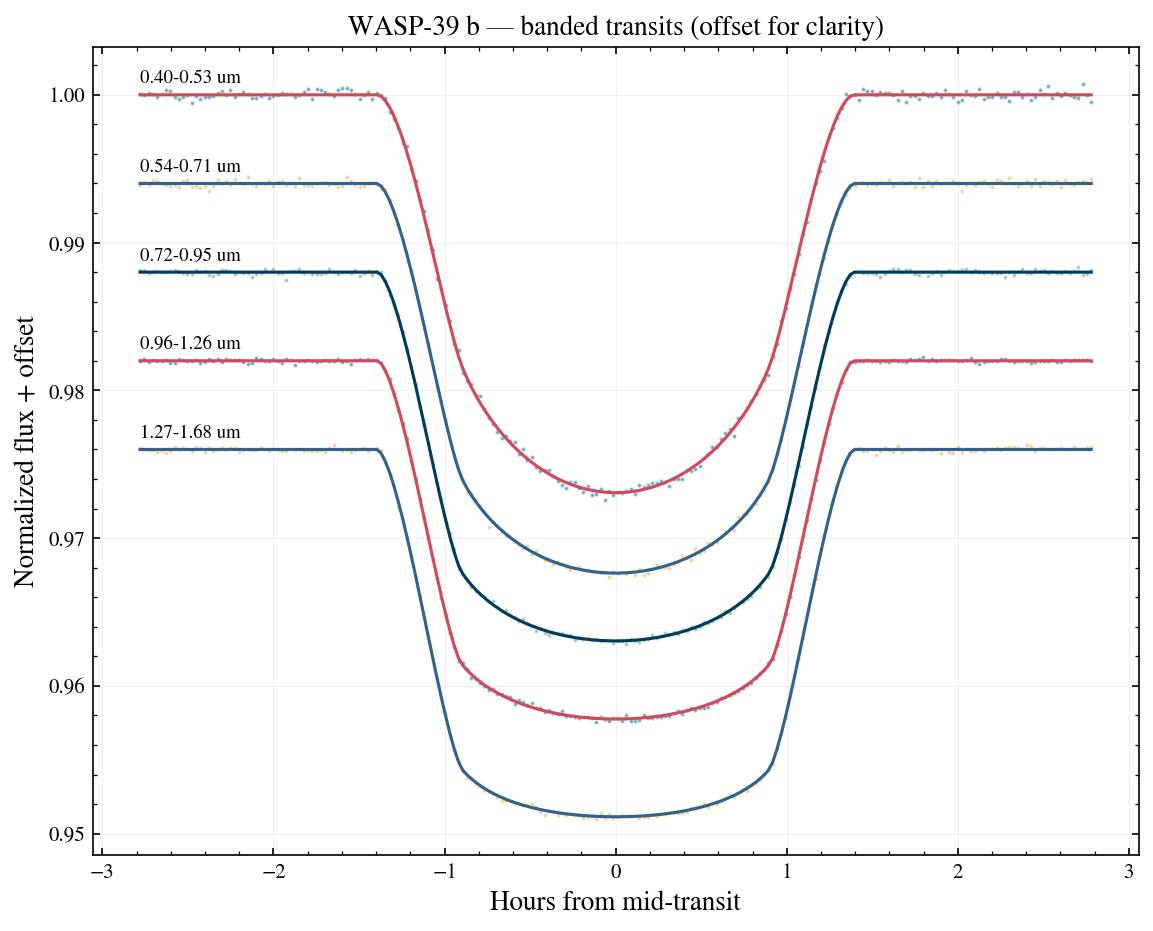

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
offset = 0.006

for i, lab in enumerate(lcb.labels):
    dy = -i * offset
    ax.plot(lcb.time_hr, lcb.flux[i] + dy, ".", ms=2, alpha=0.4)
    ax.plot(lcb.time_hr, lcb.flux_model[i] + dy, lw=1.5)
    ax.annotate(lab, (lcb.time_hr[0], 1.0 + dy + 0.0008),
                fontsize=9, ha="left")

ax.set_xlabel("Hours from mid-transit")
ax.set_ylabel("Normalized flux + offset")
ax.set_title(f"{PLANET} — banded transits (offset for clarity)")
plt.show()

## Validating `transit_flux`

The occultation model is `lazuli_exo.lightcurve.transit_flux(z, k, u1, u2)`:
normalized flux for an opaque disk of radius ratio `k` at projected
separations `z` in stellar radii. With `u1 = u2 = 0` it must reduce to the
analytic **uniform-disk** overlap, which is a closed-form expression — a
check worth running rather than assuming.

In [6]:
from lazuli_exo.lightcurve import transit_flux


def uniform_disk_flux(z, k):
    """Analytic uniform-source occultation (Mandel & Agol 2002, lambda_e)."""
    z = np.abs(np.asarray(z, float))
    out = np.ones_like(z)

    full = z <= 1.0 - k                      # planet fully on the disk
    out[full] = 1.0 - k ** 2

    part = (np.abs(1.0 - k) < z) & (z <= 1.0 + k)   # partial overlap
    zp = z[part]
    k0 = np.arccos((k ** 2 + zp ** 2 - 1.0) / (2.0 * k * zp))
    k1 = np.arccos((1.0 - k ** 2 + zp ** 2) / (2.0 * zp))
    area = (k ** 2 * k0 + k1
            - np.sqrt(4.0 * zp ** 2 - (1.0 + zp ** 2 - k ** 2) ** 2) / 2.0)
    out[part] = 1.0 - area / np.pi
    return out


z = np.linspace(0.0, 1.4, 601)
k = 0.15

numeric = transit_flux(z, k, 0.0, 0.0)
analytic = uniform_disk_flux(z, k)
err = np.abs(numeric - analytic)

print(f"k = {k}, {z.size} separations")
print(f"max |numeric - analytic|: {err.max():.3e}")
print(f"in ppm of the depth:      {err.max() / k ** 2 * 1e6:.2f} ppm")

assert err.max() < 1e-5, "uniform-disk limit must be recovered"
print("\nOK — the uniform-disk limit is recovered.")

k = 0.15, 601 separations
max |numeric - analytic|: 3.005e-07
in ppm of the depth:      13.35 ppm

OK — the uniform-disk limit is recovered.


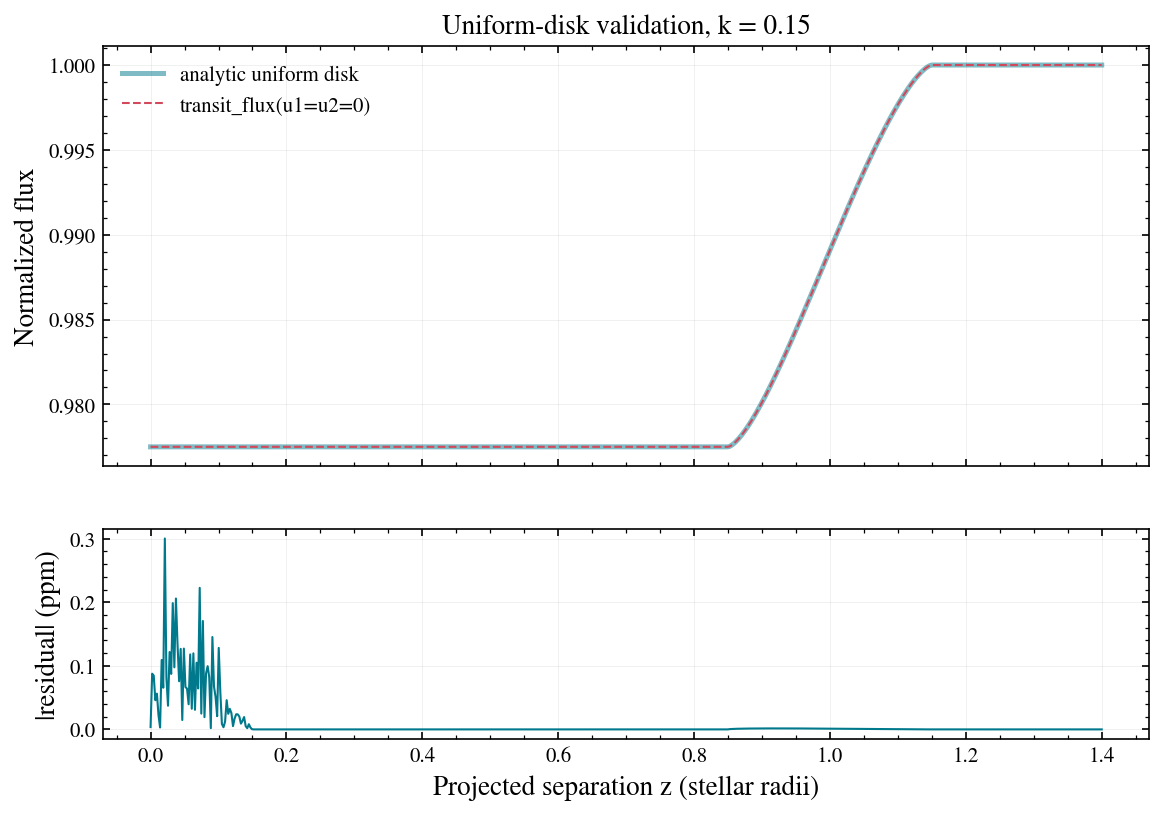

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(z, analytic, lw=2.4, alpha=0.5, label="analytic uniform disk")
ax1.plot(z, numeric, lw=1.0, ls="--", label="transit_flux(u1=u2=0)")
ax1.set_ylabel("Normalized flux")
ax1.legend(frameon=False)
ax1.set_title(f"Uniform-disk validation, k = {k}")

ax2.plot(z, err * 1e6, lw=1.0)
ax2.set_xlabel("Projected separation z (stellar radii)")
ax2.set_ylabel("|residual| (ppm)")
plt.show()

## Limb darkening

The coefficients come from per-planet tables built with exotic-ld on a
PHOENIX grid. They vary strongly across the band — much stronger limb
darkening in the blue than in the near-IR — which is why the banded curves
above change shape, not just depth.

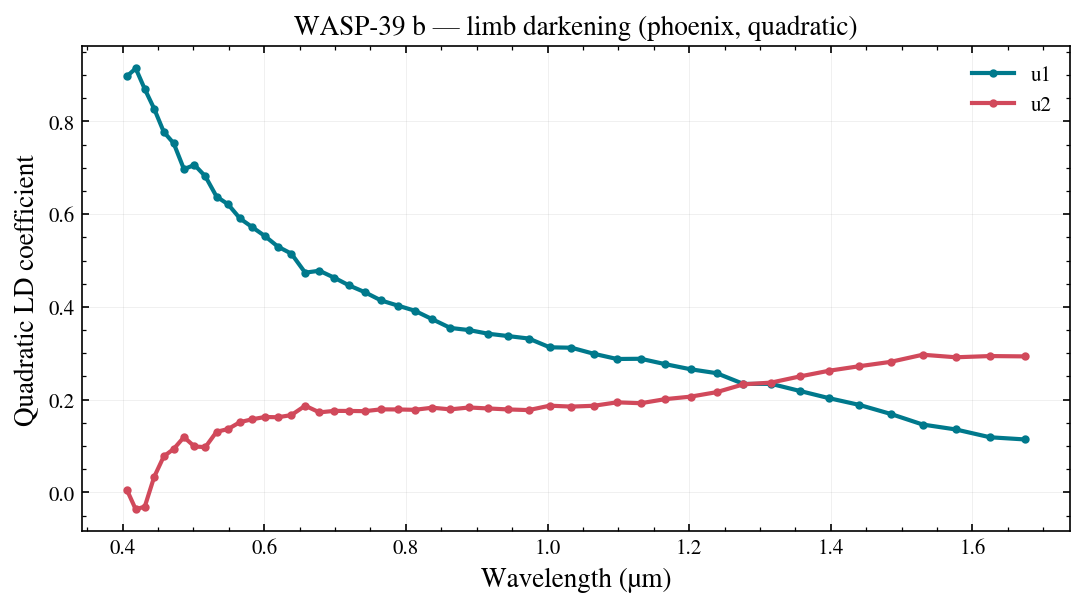

grid point used: Teff=5485.0, logg=4.453, M_H=0.01
inputs clamped to grid: []
48 wavelength chunks over [0.4, 1.7] um


In [8]:
from lazuli_exo import tables

tdir = tables.resolve_tables_dir(None)
wl_ld, u1_ld, u2_ld, ld_meta = tables.load_ld(tdir, PLANET)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(wl_ld, u1_ld, "o-", ms=3, label="u1")
ax.plot(wl_ld, u2_ld, "o-", ms=3, label="u2")
ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Quadratic LD coefficient")
ax.set_title(f"{PLANET} — limb darkening ({ld_meta['ld_grid']}, "
             f"{ld_meta['law']})")
ax.legend(frameon=False)
plt.show()

print(f"grid point used: Teff={ld_meta['Teff_used']}, "
      f"logg={ld_meta['logg_used']}, M_H={ld_meta['M_H_used']}")
print(f"inputs clamped to grid: {ld_meta['inputs_clamped']}")
print(f"{wl_ld.size} wavelength chunks over "
      f"{ld_meta['wl_range_um']} um")

The effect on the curve shape is easiest to see by holding the depth fixed
and sweeping the coefficients.

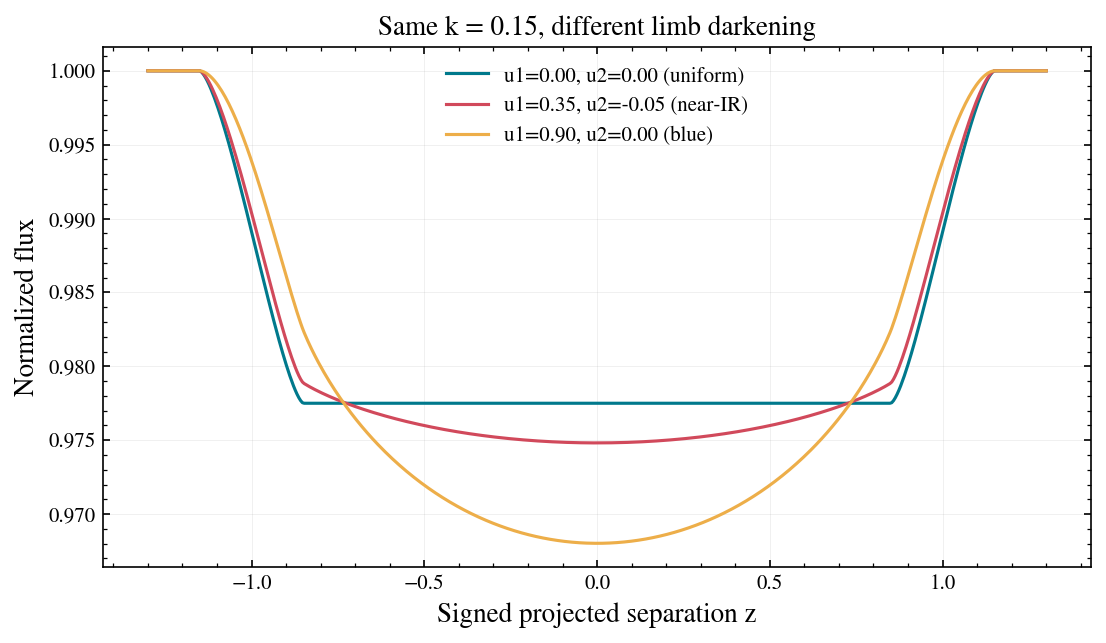

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

zz = np.linspace(-1.3, 1.3, 501)
for u1, u2, lab in [(0.0, 0.0, "u1=0.00, u2=0.00 (uniform)"),
                    (0.35, -0.05, "u1=0.35, u2=-0.05 (near-IR)"),
                    (0.90, 0.00, "u1=0.90, u2=0.00 (blue)")]:
    ax.plot(zz, transit_flux(np.abs(zz), 0.15, u1, u2), lw=1.5, label=lab)

ax.set_xlabel("Signed projected separation z")
ax.set_ylabel("Normalized flux")
ax.set_title("Same k = 0.15, different limb darkening")
ax.legend(frameon=False)
plt.show()

## Geometry from the registry

The impact parameter and orbital speed come from the frozen NEA registry:
b from a/R<sub>*</sub> and cos i with an eccentricity factor, and z(t) traced
along a local circular arc of the conjunction star–planet distance, so
z(0) = b exactly.

In [10]:
from lazuli_exo.targets import get_target

t = get_target(PLANET)
for key in ["period_d", "a_over_rs", "inc_deg", "ecc", "w_deg", "t14_s",
            "depth", "provenance"]:
    print(f"  {key:12s} {t[key]}")

print(f"\nderived by light_curves(): shape={lc.meta['shape']}, "
      f"b={lc.meta['b']:.3f}, a/Rs={lc.meta['a_over_rs']}")

  period_d     4.0552941
  a_over_rs    11.39
  inc_deg      87.32
  ecc          0.0
  w_deg        90.0
  t14_s        10091.52
  depth        0.02122849
  provenance   NEA PSCompPars

derived by light_curves(): shape=quadratic-ld, b=0.533, a/Rs=11.39


## The trapezoid fallback

If a planet is not in the registry, or has no LD table, the shape falls back
to a b = 0 trapezoid with no limb darkening. Relabelling an observation is
enough to trigger it — and `meta["shape"]` tells you it happened.

In [11]:
import dataclasses

synthetic = dataclasses.replace(obs, planet="Synthetic b")
lc_fallback = synthetic.light_curves(n_groups=1, seed=0)

print(f"registry planet: shape={lc.meta['shape']!r}, "
      f"u1={lc.u1[0]:.3f}")
print(f"synthetic name:  shape={lc_fallback.meta['shape']!r}, "
      f"u1={lc_fallback.u1}")

assert lc.meta["shape"] == "quadratic-ld"
assert lc_fallback.meta["shape"] == "trapezoid"
assert lc_fallback.u1 is None

registry planet: shape='quadratic-ld', u1=0.434
synthetic name:  shape='trapezoid', u1=None


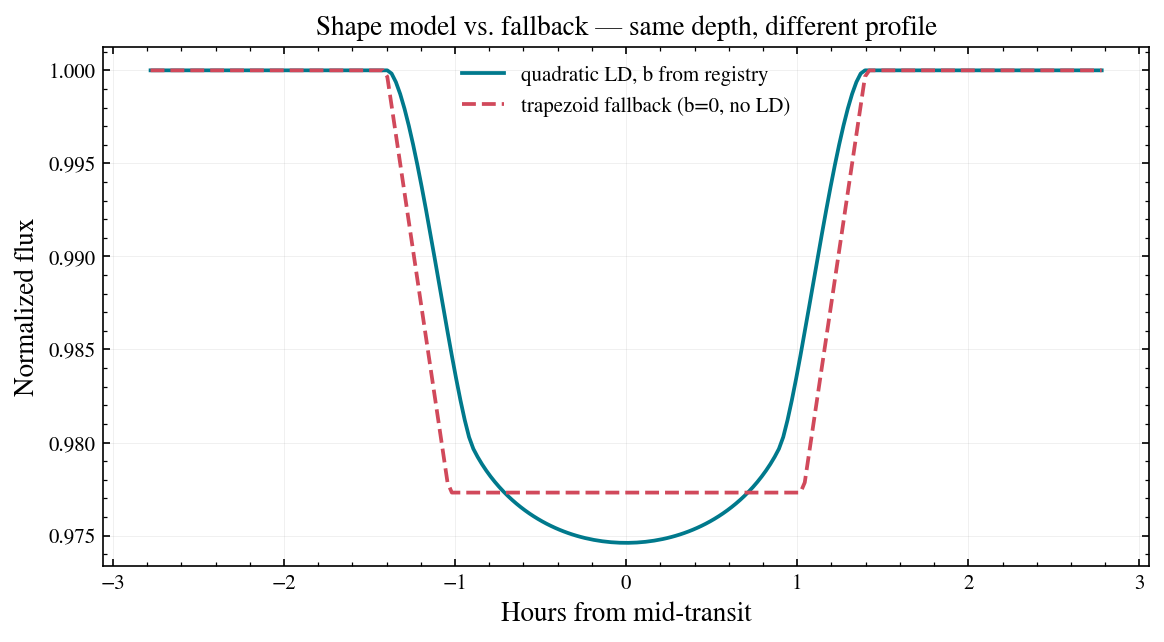

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(lc.time_hr, lc.flux_model[0], lw=1.8,
        label="quadratic LD, b from registry")
ax.plot(lc_fallback.time_hr, lc_fallback.flux_model[0], lw=1.8, ls="--",
        label="trapezoid fallback (b=0, no LD)")
ax.set_xlabel("Hours from mid-transit")
ax.set_ylabel("Normalized flux")
ax.set_title("Shape model vs. fallback — same depth, different profile")
ax.legend(frameon=False)
plt.show()

## Per-point noise

The scatter per sample is derived from the band's *depth* precision, not
computed independently: σ<sub>pt</sub> = σ<sub>band</sub> √(t<sub>14</sub>/2c)
for cadence c. This keeps the light curves consistent with the same equal
out-of-transit baseline assumption the spectra use.

In [13]:
# reconstruct the band-combined depth precision from the public arrays:
# contiguous equal-count groups, combined in inverse variance
groups = np.array_split(np.arange(obs.depth.size), 5)
w = 1.0 / obs.depth_err ** 2
sigma_band = np.array([1.0 / np.sqrt(w[g].sum()) for g in groups])

expected = sigma_band * np.sqrt(lcb.t14_s / (2.0 * lcb.cadence_s))

print(f"{'band':18s}{'sigma_band (ppm)':>18s}{'sigma_pt (ppm)':>16s}"
      f"{'expected':>12s}")
for i, lab in enumerate(lcb.labels):
    print(f"{lab:18s}{sigma_band[i] * 1e6:18.1f}"
          f"{lcb.sigma_point[i] * 1e6:16.1f}{expected[i] * 1e6:12.1f}")

assert np.allclose(lcb.sigma_point, expected)
print("\nOK — sigma_pt = sigma_band * sqrt(t14 / 2c).")

band                sigma_band (ppm)  sigma_pt (ppm)    expected
0.40-0.53 um                    32.8           245.0       245.0
0.54-0.71 um                    22.2           165.8       165.8
0.72-0.95 um                    17.8           133.2       133.2
0.96-1.26 um                    14.9           111.2       111.2
1.27-1.68 um                    15.2           113.6       113.6

OK — sigma_pt = sigma_band * sqrt(t14 / 2c).


Co-adding transits sharpens the light curves the same way it sharpens the
spectra — the per-point scatter drops as 1/√N while the model is unchanged.

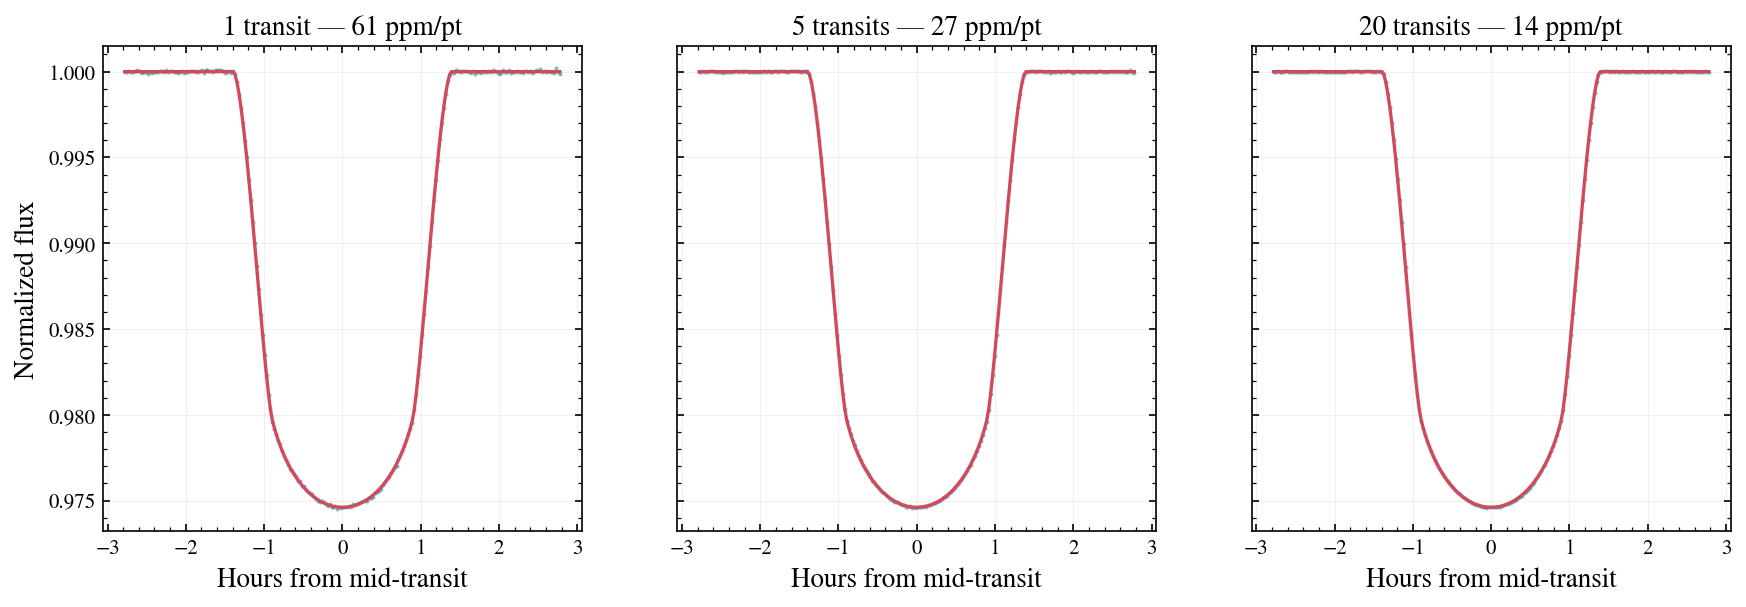

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)

for ax, n in zip(axes, [1, 5, 20]):
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=n, R=100)
    curve = o.light_curves(n_groups=1, seed=0)
    ax.plot(curve.time_hr, curve.flux[0], ".", ms=2, alpha=0.4)
    ax.plot(curve.time_hr, curve.flux_model[0], lw=1.6)
    ax.set_title(f"{n} transit{'s' if n > 1 else ''} — "
                 f"{curve.sigma_point[0] * 1e6:.0f} ppm/pt")
    ax.set_xlabel("Hours from mid-transit")

axes[0].set_ylabel("Normalized flux")
plt.show()

## Summary

- `obs.light_curves(n_groups=...)` gives white-light (`n_groups=1`) or banded
  curves over a ±t<sub>14</sub> window at the native cadence.
- `transit_flux` is a numpy-only quadratically limb-darkened occultation; it
  reproduces the analytic uniform-disk limit to well under a ppm of the depth.
- Geometry comes from the frozen NEA registry, limb darkening from exotic-ld
  tables; both are recorded in `meta`.
- No registry entry or LD table → b = 0 trapezoid, flagged as
  `meta["shape"] == "trapezoid"`.
- Per-point noise is derived from the band depth precision, so it inherits the
  equal out-of-transit baseline assumption.

Next: [tables and targets](05_tables_and_targets.ipynb) — what is actually on
disk.